# Stability of the active learning strategies across seeds

Five seeds per strategy, all with 100 starting molecules drawn at random from the library
(a plain random sample), 20 cycles and 50 oracle queries per cycle.

Runs are read from `Results/init100_randomstart_5seeds`. Each `.csv` has a `.json`
next to it recording the settings that produced it.

In [23]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rdkit import RDLogger

import analysis_utils as an
import docking_utils

RDLogger.DisableLog("rdApp.*")
sns.set_context("talk")

In [24]:
HERE = Path(_dh[-1])
RESULTS_FOLDER = HERE / ".." / "Results" / "all_seeds_2026-10-28-16-00"
FIGURE_FOLDER = RESULTS_FOLDER          # figures are saved next to the runs
AFFINITY_FILE = HERE / ".." / "data" / "recombination_library" / "predictions_skip_hyde_random_split_large.csv"

N_CYCLES = 20
TOP_NUMS = [50, 100, 500]
STRATEGIES = ["diverse", "greedy", "random"]
COLORS = {"greedy": "C0", "diverse": "C1", "random": "grey"}

## Load the runs

The strategy and seed are read from the file name, so adding more runs to the folder is
enough to include them.

In [25]:
def load_runs(folder):
    """{strategy: {seed: DataFrame}} for every result file in the folder."""
    runs = {}
    for path in sorted(Path(folder).glob("*.csv")):
        parts = path.stem.split("_")
        # skip anything that is not a result file, e.g. a table saved beside them
        if "kinodata" not in parts or not any(p.startswith("seed") for p in parts):
            continue
        strategy = parts[parts.index("kinodata") + 1]
        seed = int(next(p for p in parts if p.startswith("seed"))[4:])
        runs.setdefault(strategy, {})[seed] = pd.read_csv(path)
    return runs


runs = load_runs(RESULTS_FOLDER)
for strategy, by_seed in runs.items():
    sizes = ", ".join(f"seed {s}: {len(df)}" for s, df in sorted(by_seed.items()))
    print(f"{strategy:<9} {len(by_seed)} runs | molecules scored -> {sizes}")

diverse   10 runs | molecules scored -> seed 0: 504, seed 1: 510, seed 2: 477, seed 3: 470, seed 4: 527, seed 5: 482, seed 6: 532, seed 7: 474, seed 8: 499, seed 9: 590
greedy    10 runs | molecules scored -> seed 0: 633, seed 1: 669, seed 2: 841, seed 3: 922, seed 4: 750, seed 5: 802, seed 6: 768, seed 7: 664, seed 8: 858, seed 9: 781
random    10 runs | molecules scored -> seed 0: 752, seed 1: 775, seed 2: 779, seed 3: 773, seed 4: 796, seed 5: 757, seed 6: 711, seed 7: 792, seed 8: 824, seed 9: 772


In [26]:
# one frame with every run, for plotting
merged_df = pd.concat(
    [df.assign(strategy=strategy, seed=seed)
     for strategy, by_seed in runs.items()
     for seed, df in by_seed.items()]
)
merged_df.head()

,Unnamed: 0,cycle,oracle calls,binding affinity,SMILES,Mols,frag_ids,strategy,seed
0,0,0,0,6.699033,Cc1ccc(Cl)c(-c2ccnc(N)c2Cl)c1,<rdkit.Chem.rdchem.Mol object at 0x167dcc580>,"AP_33,FP_23",diverse,0
1,1,0,0,6.833961,Nc1nccc(-c2cc(Nc3c[nH]c4ccccc34)ccn2)n1,<rdkit.Chem.rdchem.Mol object at 0x31350fe60>,"AP_66,FP_60,SE_17",diverse,0
2,2,0,0,6.212408,Nc1ncc(-c2cc3ccccc3cn2)cc1-c1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x324d5e500>,"AP_37,FP_8,SE_40",diverse,0
3,3,0,0,6.261606,COc1cnc(-c2ccc3c(c2)CCO3)nc1,<rdkit.Chem.rdchem.Mol object at 0x167d98510>,"AP_43,SE_39",diverse,0
4,4,0,0,6.863263,c1cnc2cc(-c3c(-c4ccc5c(c4)CCO5)cnc4[nH]ncc34)[...,<rdkit.Chem.rdchem.Mol object at 0x1741163b0>,"AP_35,FP_89,SE_39",diverse,0


## Predicted binding affinity per cycle

Thin lines are the individual seeds, thick lines the mean per strategy. The spread between
thin lines of the same colour is the run-to-run variation.

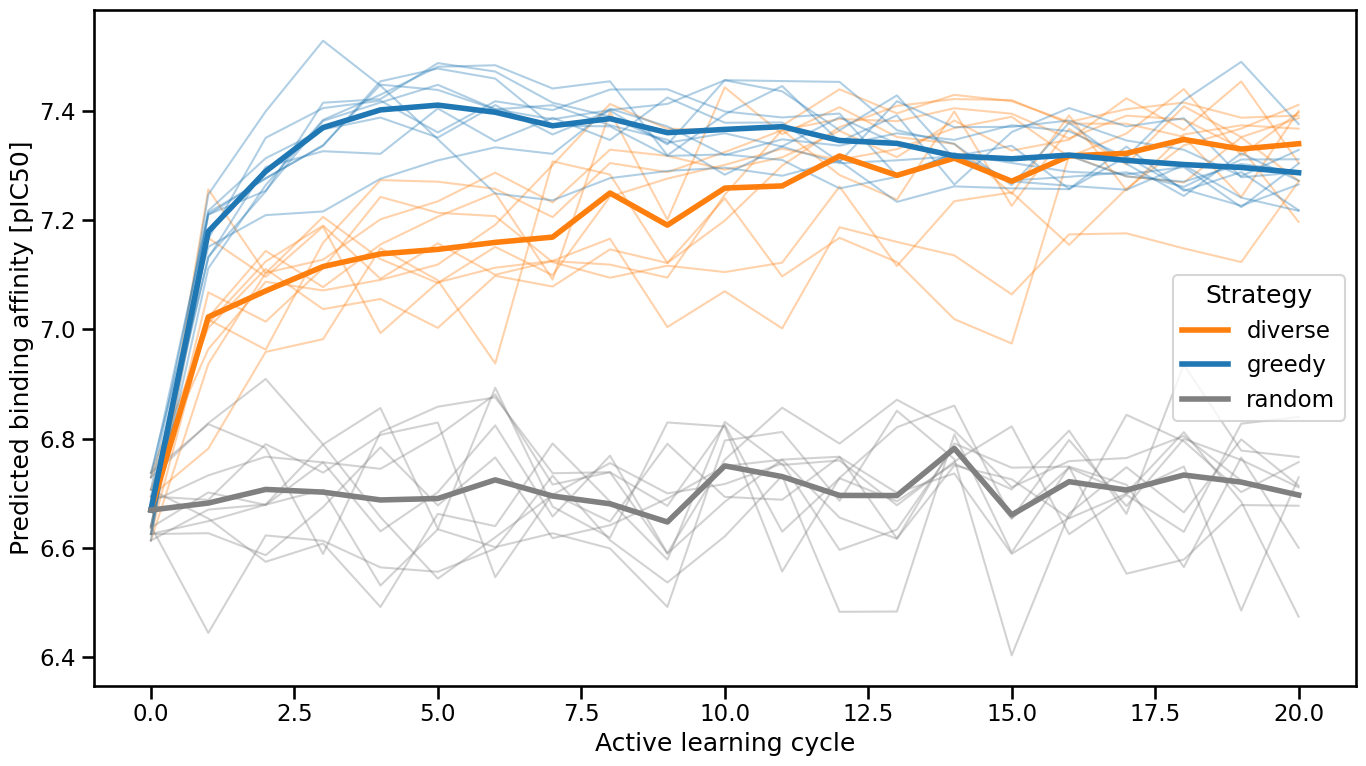

In [27]:
fig, ax = plt.subplots(figsize=(14, 8))

for strategy, by_seed in runs.items():
    for seed, df in by_seed.items():
        means = df.groupby("cycle")["binding affinity"].mean()
        ax.plot(means.index, means.values, color=COLORS[strategy], alpha=0.35, linewidth=1.5)

for strategy, by_seed in runs.items():
    per_seed = pd.concat(
        [df.groupby("cycle")["binding affinity"].mean().rename(seed) for seed, df in by_seed.items()],
        axis=1,
    )
    ax.plot(per_seed.index, per_seed.mean(axis=1), color=COLORS[strategy], linewidth=4, label=strategy)

ax.set_xlabel("Active learning cycle")
ax.set_ylabel("Predicted binding affinity [pIC50]")
ax.legend(title="Strategy")
plt.tight_layout()
plt.show()

## How much of the best chemical space each run found

In [28]:
sorted_affs = an.sort_affinities(docking_utils.read_affinities(str(AFFINITY_FILE)))
top_sets = {k: {frag for frag, _ in sorted_affs[:k]} for k in TOP_NUMS}

rows = []
for strategy, by_seed in runs.items():
    for seed, df in sorted(by_seed.items()):
        found = set(df.frag_ids)
        row = {"strategy": strategy, "seed": seed, "molecules": len(df),
               "best": df["binding affinity"].max()}
        for k in TOP_NUMS:
            row[f"top{k}"] = len(found & top_sets[k])
        rows.append(row)

recovery_df = pd.DataFrame(rows)
recovery_df

,strategy,seed,molecules,best,top50,top100,top500
0,diverse,0,504,7.849481,9,16,35
1,diverse,1,510,7.829085,8,12,47
2,diverse,2,477,7.737165,11,22,61
3,diverse,3,470,7.737165,4,4,25
4,diverse,4,527,7.937722,17,32,83
5,diverse,5,482,7.932767,21,29,85
6,diverse,6,532,7.933512,13,25,81
7,diverse,7,474,7.937722,16,24,79
8,diverse,8,499,7.937722,18,32,103
9,diverse,9,590,7.937722,24,43,114


In [29]:
summary = recovery_df.groupby("strategy").agg(["mean", "std"]).round(2)
summary = summary[["molecules", "best"] + [f"top{k}" for k in TOP_NUMS]]
summary

molecules         best       top50       top100        top500       
              mean    std  mean   std  mean   std   mean    std   mean    std
strategy                                                                     
diverse      506.5  36.48  7.88  0.08  14.1  6.23   23.9  11.19   71.3  28.80
greedy       768.8  92.87  7.93  0.03  24.9  6.24   41.7   8.83  137.8  24.97
random       773.1  29.95  7.68  0.12   0.4  0.70    1.6   1.35    6.7   3.02

The standard deviation is what this notebook is about: a strategy that is better on average
but swings wildly between seeds is harder to rely on than a steadier one.

/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Users/paulakramer/micromamba/envs/act_learn_arm/l

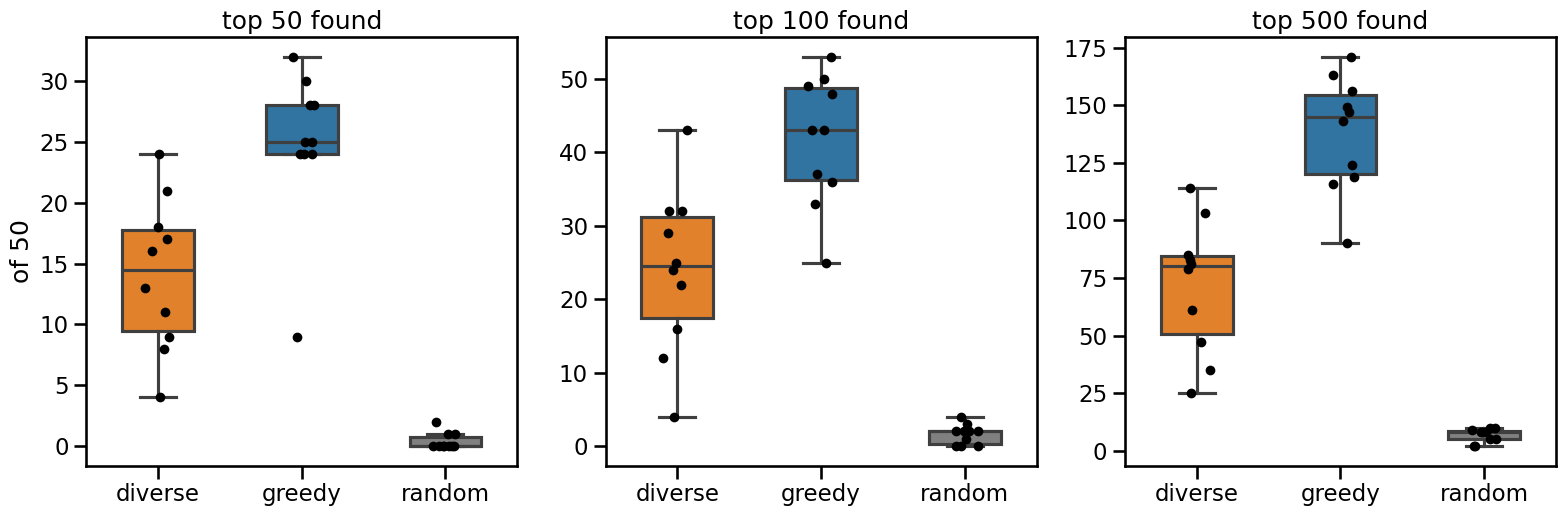

In [30]:
fig, axes = plt.subplots(1, len(TOP_NUMS), figsize=(16, 5.5))
for ax, k in zip(axes, TOP_NUMS):
    sns.boxplot(data=recovery_df, x="strategy", y=f"top{k}", order=STRATEGIES,
                palette=[COLORS[s] for s in STRATEGIES], ax=ax, width=0.5, fliersize=0)
    sns.stripplot(data=recovery_df, x="strategy", y=f"top{k}", order=STRATEGIES,
                  color="black", size=7, ax=ax)
    ax.set_title(f"top {k} found")
    ax.set_ylabel(f"of {k}" if ax is axes[0] else "")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Recovery over the cycles

Mean across seeds, with the shaded band covering one standard deviation.

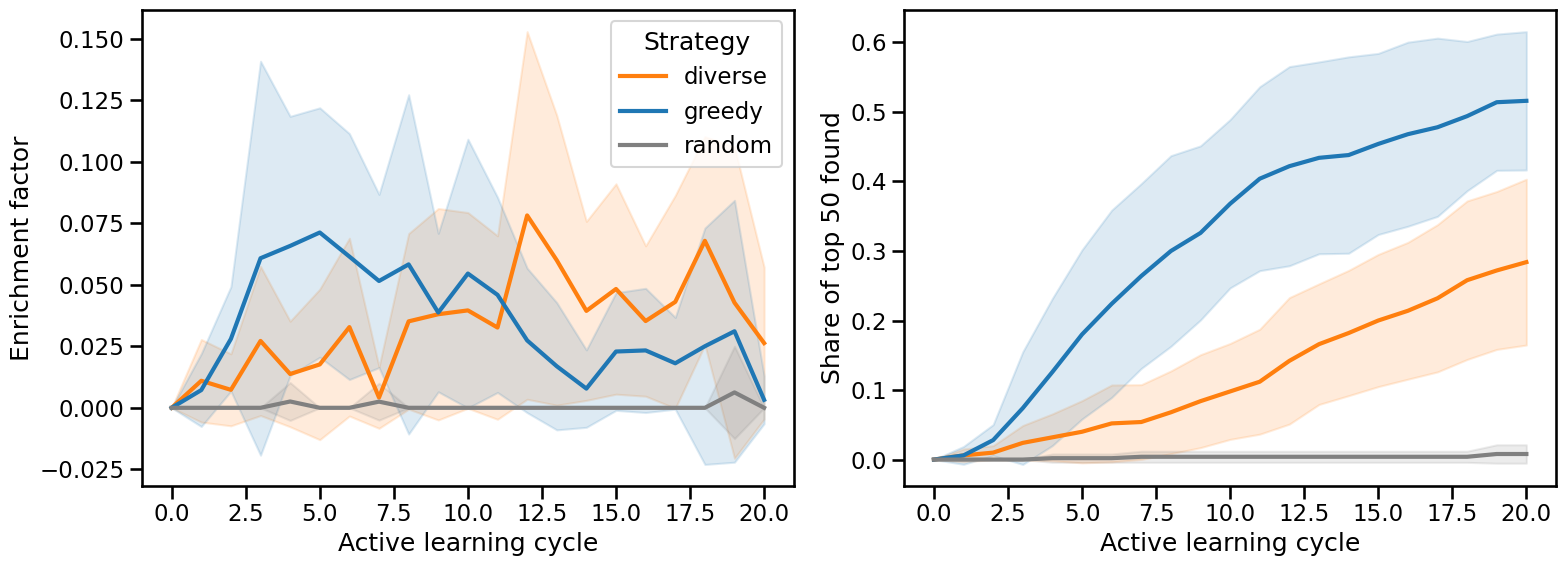

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

for strategy, by_seed in runs.items():
    per_cycle, cumulative = [], []
    for seed, df in by_seed.items():
        fractions = an.top_fractions_per_cycle(df, sorted_affs, [TOP_NUMS[0]], N_CYCLES)
        cum, _ = an.cumulative_top_fractions(df, fractions, [TOP_NUMS[0]])
        per_cycle.append(fractions[0])
        cumulative.append(cum[0])
    for ax, values, label in ((axes[0], np.array(per_cycle), "Enrichment factor"),
                              (axes[1], np.array(cumulative), f"Share of top {TOP_NUMS[0]} found")):
        mean, sd = values.mean(axis=0), values.std(axis=0)
        x = range(len(mean))
        ax.plot(x, mean, color=COLORS[strategy], linewidth=3, label=strategy)
        ax.fill_between(x, mean - sd, mean + sd, color=COLORS[strategy], alpha=0.15)
        ax.set_ylabel(label)
        ax.set_xlabel("Active learning cycle")

axes[0].legend(title="Strategy")
plt.tight_layout()
plt.show()

## Diversity of the selected molecules

In [32]:
diversity_rows = []
total_fragments = an.count_total_fragments(docking_utils.read_affinities(str(AFFINITY_FILE)))
for strategy, by_seed in runs.items():
    for seed, df in by_seed.items():
        diversity_rows.append({
            "strategy": strategy,
            "seed": seed,
            "fragment diversity": an.fragment_diversity(df, total_fragments, N_CYCLES)[-1],
            "molecular diversity": np.nanmean(an.molecular_diversity(an.add_fingerprints(df), N_CYCLES)),
        })
diversity_df = pd.DataFrame(diversity_rows)
diversity_df.groupby("strategy").agg(["mean", "std"]).round(3)

seed        fragment diversity        molecular diversity       
         mean    std               mean    std                mean    std
strategy                                                                 
diverse   4.5  3.028              0.632  0.023               0.714  0.019
greedy    4.5  3.028              0.679  0.018               0.693  0.018
random    4.5  3.028              0.785  0.023               0.812  0.003

/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Users/paulakramer/micromamba/envs/act_learn_arm/l

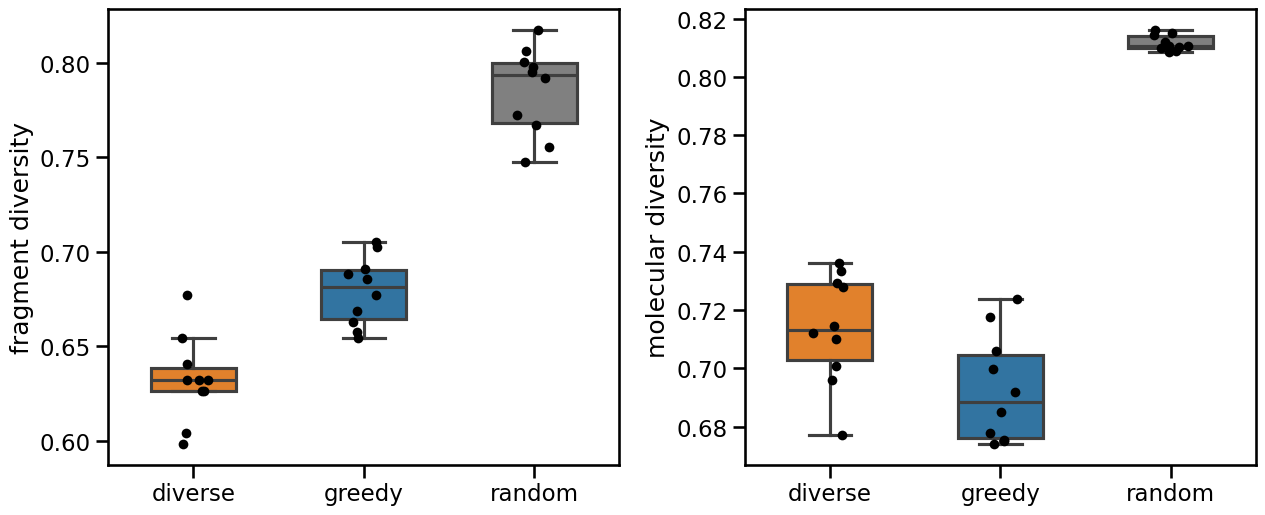

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, column in zip(axes, ["fragment diversity", "molecular diversity"]):
    sns.boxplot(data=diversity_df, x="strategy", y=column, order=STRATEGIES,
                palette=[COLORS[s] for s in STRATEGIES], ax=ax, width=0.5, fliersize=0)
    sns.stripplot(data=diversity_df, x="strategy", y=column, order=STRATEGIES,
                  color="black", size=7, ax=ax)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Oracle calls spent

Every run gets the same budget, but molecules without a value in the affinity table are
discarded, so the strategies end up with different numbers of usable results.

/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/paulakramer/micromamba/envs/act_learn_arm/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


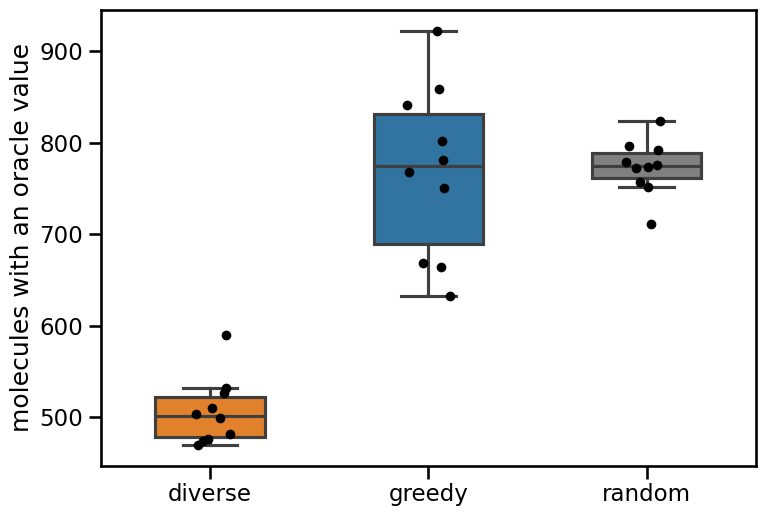

           mean   std
strategy             
diverse   506.5  36.5
greedy    768.8  92.9
random    773.1  29.9


In [34]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=recovery_df, x="strategy", y="molecules", order=STRATEGIES,
            palette=[COLORS[s] for s in STRATEGIES], ax=ax, width=0.5, fliersize=0)
sns.stripplot(data=recovery_df, x="strategy", y="molecules", order=STRATEGIES,
              color="black", size=7, ax=ax)
ax.set_ylabel("molecules with an oracle value")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print(recovery_df.groupby("strategy")["molecules"].agg(["mean", "std"]).round(1))

## Distribution of the scored chemical space

Where the top 50, 100 and 500 cut-offs sit in the whole set of precomputed affinities.

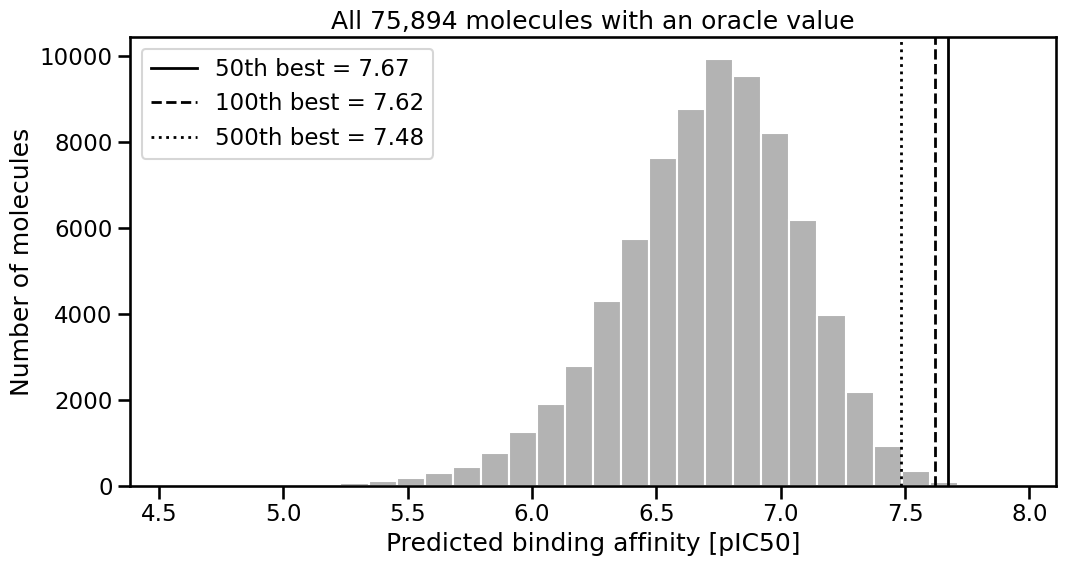

In [35]:
affinity_values = np.array([value for _, value in sorted_affs])

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(affinity_values, bins=30, color="0.7", edgecolor="white")
for k, style in zip(TOP_NUMS, ["-", "--", ":"]):
    ax.axvline(affinity_values[k - 1], color="black", linestyle=style, linewidth=2,
               label=f"{k}th best = {affinity_values[k - 1]:.2f}")
ax.set_xlabel("Predicted binding affinity [pIC50]")
ax.set_ylabel("Number of molecules")
ax.set_title(f"All {len(affinity_values):,} molecules with an oracle value")
ax.legend()
plt.tight_layout()
plt.show()

## Every run in one figure

One line per run, coloured by strategy: predicted affinity per cycle, then the share of the
top 50 and of the top 100 found up to each cycle. The spread between lines of the same
colour is the run-to-run stability.

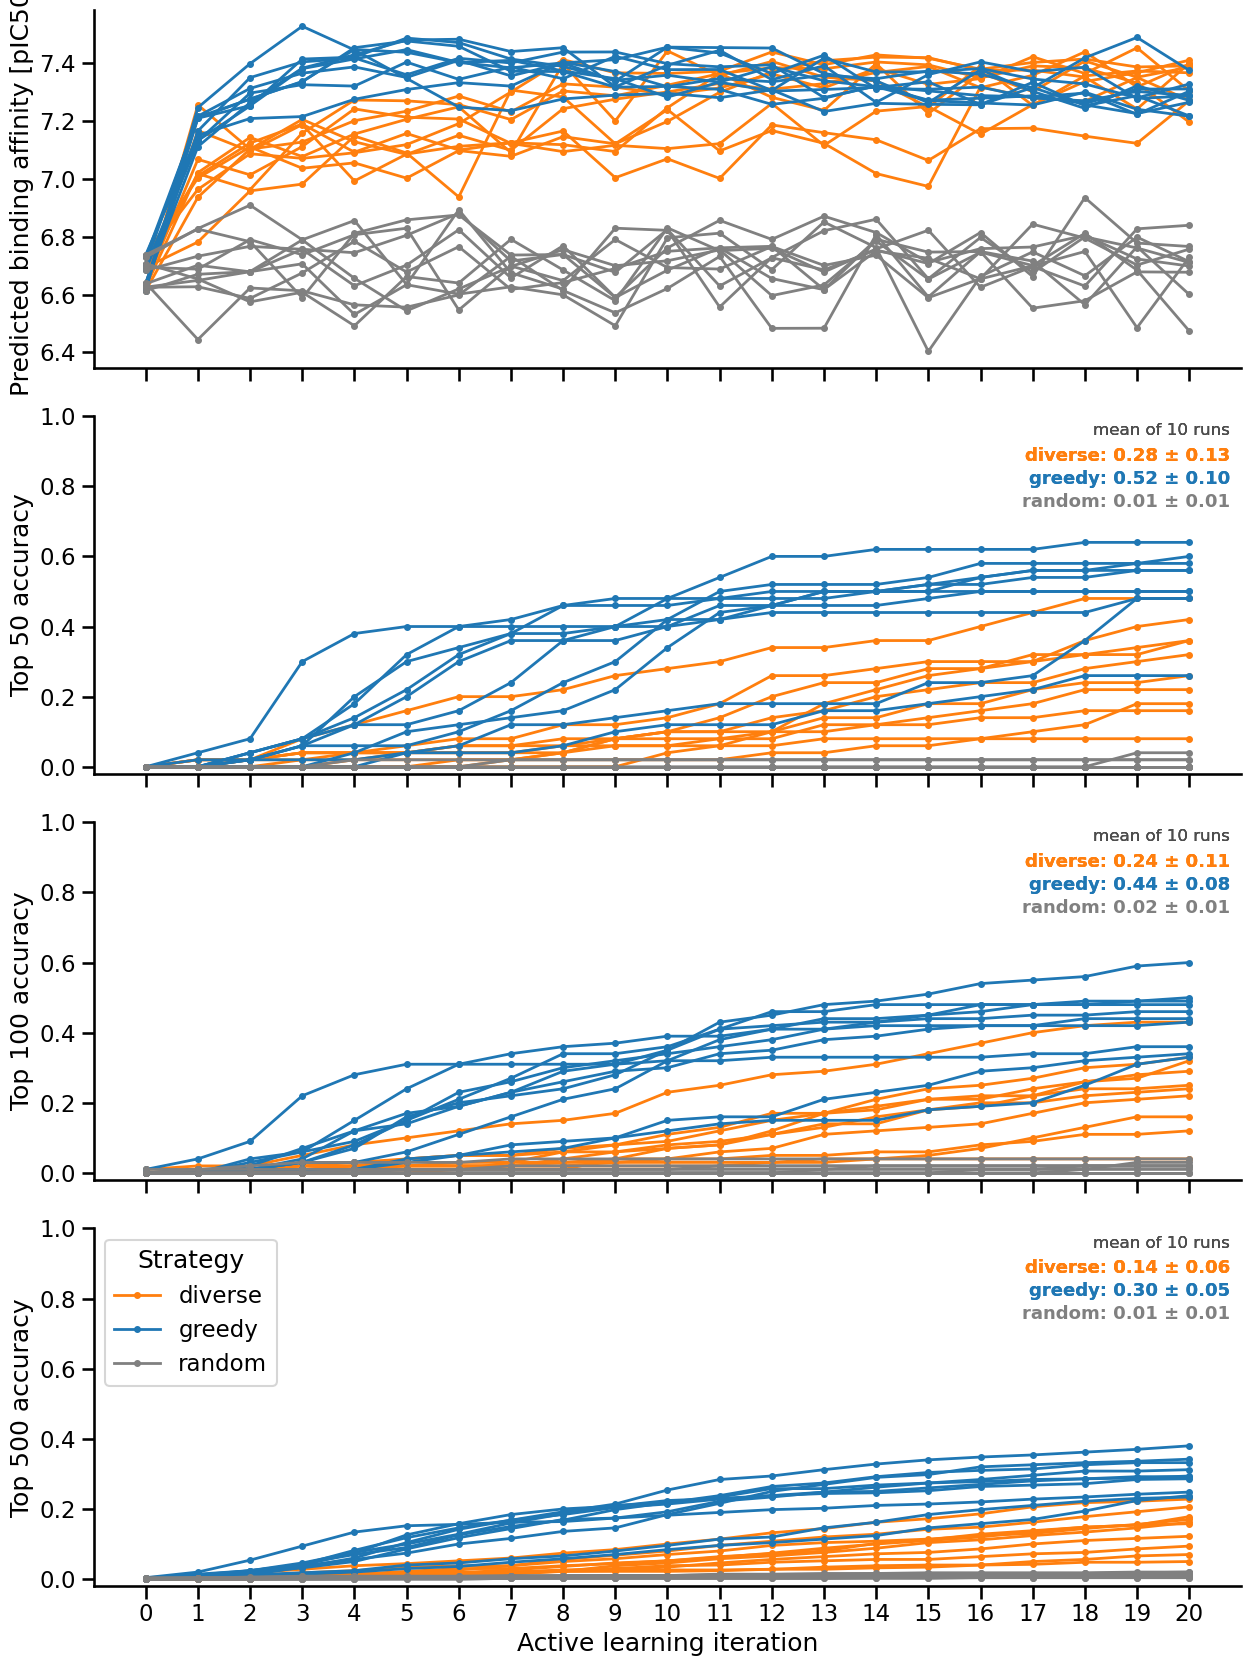

In [36]:
def cumulative_top(df, k):
    """Share of the overall top k found up to and including each cycle."""
    fractions = an.top_fractions_per_cycle(df, sorted_affs, [k], N_CYCLES)
    cumulative, _ = an.cumulative_top_fractions(df, fractions, [k])
    return cumulative[0]


fig, axes = plt.subplots(4, 1, figsize=(13, 17), sharex=True)
labelled = set()
finals = {k: {strategy: [] for strategy in STRATEGIES} for k in TOP_NUMS}

for strategy in STRATEGIES:
    for seed, df in sorted(runs[strategy].items()):
        label = None if strategy in labelled else strategy
        labelled.add(strategy)
        means = df.groupby("cycle")["binding affinity"].mean()
        axes[0].plot(means.index, means.values, color=COLORS[strategy],
                     marker="o", markersize=4, linewidth=2, label=label)
        for ax, k in zip(axes[1:], TOP_NUMS):
            values = cumulative_top(df, k)
            finals[k][strategy].append(values[-1])
            ax.plot(range(len(values)), values, color=COLORS[strategy],
                    marker="o", markersize=4, linewidth=2)
    
    for ax, k in zip(axes[1:], TOP_NUMS):
        ax.text(0.99, 0.98, f"mean of {len(finals[k][STRATEGIES[0]])} runs",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=12, color="0.3")
        for row, strategy in enumerate(STRATEGIES, start=1):
            reached = finals[k][strategy]
            if not reached:
                continue
            ax.text(0.99, 0.98 - row * 0.065,
                    f"{strategy}: {np.mean(reached):.2f} ± {np.std(reached, ddof=1):.2f}",
                    transform=ax.transAxes, ha="right", va="top",
                    fontsize=13, fontweight="bold", color=COLORS[strategy])

axes[0].set_ylabel("Predicted binding affinity [pIC50]")
#axes[0].legend(title="Strategy")
axes[1].set_ylabel(f"Top {TOP_NUMS[0]} accuracy")
axes[1].set_ylim(-0.02, 1)
axes[2].set_ylabel(f"Top {TOP_NUMS[1]} accuracy")
axes[2].set_ylim(-0.02, 1)
axes[3].set_ylim(-0.02, 1)
axes[3].set_ylabel(f"Top {TOP_NUMS[2]} accuracy")
axes[3].set_xlabel("Active learning iteration")
axes[3].set_xticks(range(0, N_CYCLES + 1))
handles, labels = axes[0].get_legend_handles_labels()
axes[3].legend(handles, labels, title="Strategy", loc="upper left")
sns.despine()
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "active_learning_stability_init100.svg", format="svg")
plt.show()

## Ligand uniqueness

How often the same ligand is found by different runs of the same strategy. A ligand found
by all runs is one the strategy reaches reliably; one found by a single run is luck.

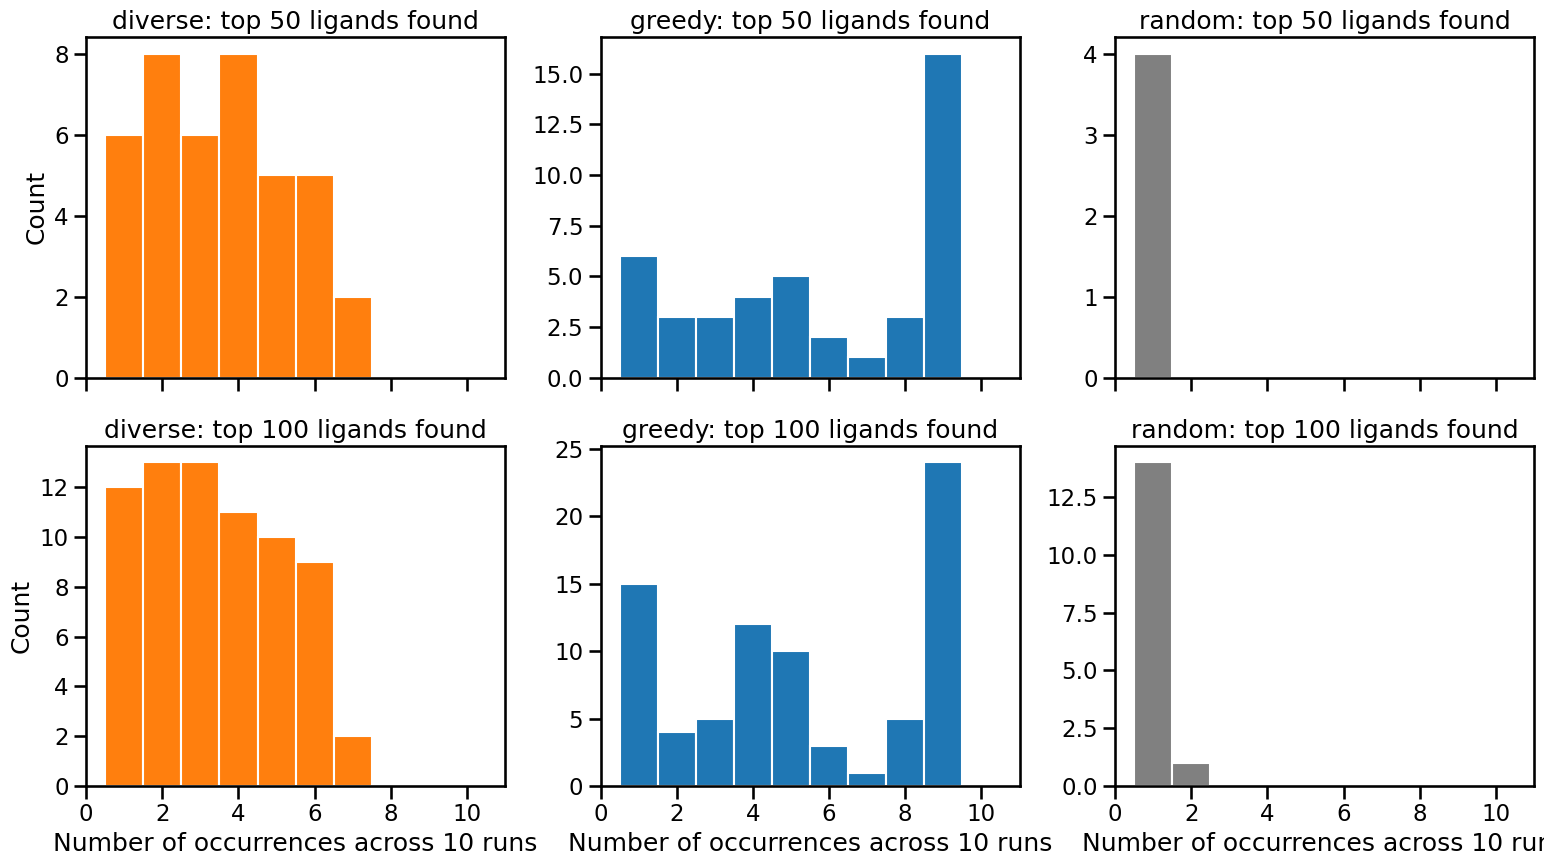

In [37]:
n_runs = max(len(by_seed) for by_seed in runs.values())
unique_per_strategy = {
    strategy: pd.concat([df.drop_duplicates(subset="frag_ids") for df in by_seed.values()])
    for strategy, by_seed in runs.items()
}

bins = np.arange(0.5, n_runs + 1.5, 1)
fig, axes = plt.subplots(2, len(STRATEGIES), figsize=(16, 9), sharex=True)

for col, strategy in enumerate(STRATEGIES):
    merged = unique_per_strategy[strategy]
    counts_top50 = merged[merged.frag_ids.isin(top_sets[50])]["frag_ids"].value_counts()
    counts_top100 = merged[merged.frag_ids.isin(top_sets[100])]["frag_ids"].value_counts()

    axes[0][col].hist(counts_top50, bins=bins, color=COLORS[strategy], edgecolor="white")
    axes[0][col].set_title(f"{strategy}: top 50 ligands found")
    axes[1][col].hist(counts_top100, bins=bins, color=COLORS[strategy], edgecolor="white")
    axes[1][col].set_title(f"{strategy}: top 100 ligands found")
    axes[1][col].set_xlabel(f"Number of occurrences across {n_runs} runs")

axes[0][0].set_ylabel("Count")
axes[1][0].set_ylabel("Count")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "uniqueness_init100.svg", format="svg")
plt.show()

In [38]:
rows = []
for strategy, merged in unique_per_strategy.items():
    counts_top = merged[merged.frag_ids.isin(top_sets[100])]["frag_ids"].value_counts()
    counts_all = merged["frag_ids"].value_counts()
    rows.append({
        "strategy": strategy,
        "distinct top 100 ligands found": len(counts_top),
        "found by every run": int((counts_top == n_runs).sum()),
        "found by one run only": int((counts_top == 1).sum()),
        "distinct ligands overall": len(counts_all),
        "overlap between runs": round(1 - len(counts_all) / sum(len(df) for df in runs[strategy].values()), 3),
    })
pd.DataFrame(rows).set_index("strategy")

,distinct top 100 ligands found,found by every run,found by one run only,distinct ligands overall,overlap between runs
strategy,,,,,
diverse,70,0,12,3314,0.346
greedy,79,0,15,3410,0.556
random,15,0,14,7257,0.061


## Significance testing

Every strategy sees the same starting set for a given seed, so the runs are **paired**:
seed 3 of greedy and seed 3 of diverse began from the same 100 molecules. The tests below
use that pairing, which is what makes ten seeds enough to say anything at all.

The unit of replication is the **run**, not the molecule. Pooling all molecules of all runs
and comparing those would treat 7,688 greedy molecules as 7,688 independent observations,
when they come from ten runs and are strongly correlated within a run. That inflates the
sample size enormously and would call almost any difference significant.

So: a Friedman test across the three strategies first, then pairwise Wilcoxon signed rank
tests as a post hoc, with Holm correction over the three pairs of each metric.

In [39]:
from itertools import combinations

from scipy import stats

ALPHA = 0.05
BOOTSTRAP = 10_000      # resamples for the confidence interval of the median difference


def holm(pvalues):
    """Holm-Bonferroni adjusted p values, returned in the order given."""
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.0
    for rank, index in enumerate(order):
        # the step down: each p is scaled by how many tests are still open
        running = max(running, (len(pvalues) - rank) * pvalues[index])
        adjusted[index] = min(1.0, running)
    return adjusted


def paired(table, metric):
    """Seeds as rows, strategies as columns, so a row is one starting set."""
    wide = table.pivot(index="seed", columns="strategy", values=metric)
    return wide.dropna()


def rank_biserial(differences):
    """Matched pairs rank biserial correlation, the effect size that fits Wilcoxon.

    +1 means every seed favours A, -1 means every seed favours B, 0 is an even split.
    """
    differences = differences[differences != 0]
    if len(differences) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(differences))
    return (ranks[differences > 0].sum() - ranks[differences < 0].sum()) / ranks.sum()


def median_difference_ci(differences, resamples=BOOTSTRAP, seed=0):
    """Percentile bootstrap interval for the median paired difference."""
    rng = np.random.default_rng(seed)
    draws = rng.choice(differences, size=(resamples, len(differences)), replace=True)
    return np.percentile(np.median(draws, axis=1), [2.5, 97.5])

### Does any strategy differ at all?

Friedman is the repeated measures test for three or more paired groups. A large p here
means the metric does not separate the strategies, and the pairwise tests below are not
worth reading for that row.

In [40]:
METRICS = [f"top{k}" for k in TOP_NUMS] + ["best"]

rows = []
for metric in METRICS:
    wide = paired(recovery_df, metric)
    present = [s for s in STRATEGIES if s in wide.columns]
    statistic, p = stats.friedmanchisquare(*[wide[s] for s in present])
    rows.append({"metric": metric, "n seeds": len(wide), "strategies": len(present),
                 "Friedman chi2": round(statistic, 2), "p": p,
                 "differs": p < ALPHA})
friedman_df = pd.DataFrame(rows).set_index("metric")
friedman_df

,n seeds,strategies,Friedman chi2,p,differs
metric,,,,,
top50,10,3,17.90,0.000130,True
top100,10,3,18.20,0.000112,True
top500,10,3,20.00,0.000045,True
best,10,3,15.08,0.000531,True


### Which pairs differ

Two sided Wilcoxon signed rank on the paired per seed values, Holm corrected within each
metric. `median difference` is A minus B, so a positive number favours A, and `ties` counts
the seeds where the two strategies came out equal, which carry no weight in the test.

**What the metrics mean.** The oracle holds a predicted pIC50 for each of the 75,894
scored ligands of the library, and higher is better. Ranking all of them best first gives
the reference the runs are measured against.

- `top50`, `top100`, `top500`: how many of the 50, 100 or 500 best ligands **in the whole
  library** this run actually selected and had scored. The maximum is k, so top100 = 43
  means the run found 43 of the 100 best ligands that exist. It is a recall, not a score.
- `best`: the highest predicted pIC50 among the molecules the run scored, so a single
  number describing its one best find. The best ligand in the library scores 7.938, which
  is the ceiling for this column.

The two say different things. `best` only asks whether a run got lucky once, and saturates
quickly because many ligands sit near the top of the range. `top k` asks how much of the
good region the run actually mapped, which is why it separates the strategies far more
sharply.

In [41]:
def compare(table, metric, strategies=STRATEGIES, alpha=ALPHA):
    """Pairwise paired comparisons of one metric between strategies."""
    wide = paired(table, metric)
    present = [s for s in strategies if s in wide.columns]
    rows = []
    for a, b in combinations(present, 2):
        differences = (wide[a] - wide[b]).to_numpy(dtype=float)
        # pairs where the two strategies tie carry no information for the signed rank
        # test. Dropping them here lets scipy use the exact distribution instead of
        # falling back to a normal approximation and warning that n is too small for it.
        informative = differences[differences != 0]
        if len(informative) == 0:
            statistic, p = np.nan, 1.0        # identical on every seed
        else:
            statistic, p = stats.wilcoxon(informative, method="exact")
        low, high = median_difference_ci(differences)
        # kept twice: the string reads well in the table, the pair is used by the summary
        rows.append({
            "metric": metric, "A": a, "B": b, "n": len(wide),
            "ties": len(differences) - len(informative),
            "median A": wide[a].median(), "median B": wide[b].median(),
            "median difference": np.median(differences),
            "95% CI": f"[{low:.3g}, {high:.3g}]",
            "ci": (low, high),
            "effect size": round(rank_biserial(differences), 2),
            "W": statistic, "p": p,
        })
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"])
    out["significant"] = out["p (Holm)"] < alpha
    return out


pairwise_df = pd.concat([compare(recovery_df, metric) for metric in METRICS],
                        ignore_index=True)
pairwise_df.round(4)

,metric,A,B,n,ties,median A,median B,median difference,95% CI,ci,effect size,W,p,p (Holm),significant
0,top50,diverse,greedy,10,1,14.5000,25.0000,-13.0000,"[-19, -4]","(-19.0, -4.0)",-0.91,2.0,0.0117,0.0117,True
1,top50,diverse,random,10,0,14.5000,0.0000,14.0000,"[9, 18.5]","(9.0, 18.5)",1.00,0.0,0.0020,0.0059,True
2,top50,greedy,random,10,0,25.0000,0.0000,24.5000,"[23, 28.5]","(23.0, 28.5)",1.00,0.0,0.0020,0.0059,True
3,top100,diverse,greedy,10,0,24.5000,43.0000,-21.0000,"[-28, -5]","(-28.0, -5.0)",-0.89,3.0,0.0098,0.0098,True
4,top100,diverse,random,10,0,24.5000,2.0000,23.5000,"[15, 28]","(15.0, 28.0)",1.00,0.0,0.0020,0.0059,True
5,top100,greedy,random,10,0,43.0000,2.0000,41.0000,"[33.5, 49]","(33.5, 49.0)",1.00,0.0,0.0020,0.0059,True
6,top500,diverse,greedy,10,0,80.0000,145.0000,-66.0000,"[-110, -33]","(-110.0, -33.0)",-1.00,0.0,0.0020,0.0059,True
7,top500,diverse,random,10,0,80.0000,8.0000,71.0000,"[42, 84.5]","(42.0, 84.5)",1.00,0.0,0.0020,0.0059,True
8,top500,greedy,random,10,0,145.0000,8.0000,139.5000,"[114, 150]","(114.0, 149.5)",1.00,0.0,0.0020,0.0059,True
9,best,diverse,greedy,10,3,7.9331,7.9377,-0.0046,"[-0.144, 0]","(-0.1443988323211669, 0.0)",-0.79,3.0,0.0781,0.0781,False


### The same for the diversity measures

In [42]:
diversity_metrics = ["fragment diversity", "molecular diversity"]

diversity_tests = pd.concat(
    [compare(diversity_df, metric) for metric in diversity_metrics], ignore_index=True
)
diversity_tests.round(4)

,metric,A,B,n,ties,median A,median B,median difference,95% CI,ci,effect size,W,p,p (Holm),significant
0,fragment diversity,diverse,greedy,10,0,0.6320,0.6812,-0.0520,"[-0.073, -0.0225]","(-0.07303370786516855, -0.022471910112359494)",-0.93,2.0,0.0059,0.0059,True
1,fragment diversity,diverse,random,10,0,0.6320,0.7935,-0.1615,"[-0.178, -0.124]","(-0.1783707865168539, -0.1235955056179775)",-1.00,0.0,0.0020,0.0059,True
2,fragment diversity,greedy,random,10,0,0.6812,0.7935,-0.0969,"[-0.14, -0.0829]","(-0.1404494382022471, -0.0828651685393259)",-1.00,0.0,0.0020,0.0059,True
3,molecular diversity,diverse,greedy,10,0,0.7133,0.6885,0.0307,"[-0.00568, 0.0436]","(-0.005681109637437343, 0.043590649886190436)",0.71,8.0,0.0488,0.0488,True
4,molecular diversity,diverse,random,10,0,0.7133,0.8106,-0.0980,"[-0.11, -0.081]","(-0.10982911667362194, -0.08097865343042465)",-1.00,0.0,0.0020,0.0059,True
5,molecular diversity,greedy,random,10,0,0.6885,0.8106,-0.1214,"[-0.134, -0.105]","(-0.13399682447095723, -0.10473383911207645)",-1.00,0.0,0.0020,0.0059,True


### How much can ten seeds actually resolve

The signed rank test has a floor: with n paired seeds there is a smallest p it can return,
reached when every seed points the same way. Worth printing, so a p that sits at the floor
is not mistaken for a weak result, and so the cost of adding seeds is visible.

In [43]:
rows = []
for n in range(5, 16):
    # every difference positive is the most extreme outcome possible for n pairs
    floor = stats.wilcoxon(np.arange(1, n + 1), np.zeros(n)).pvalue
    rows.append({"seeds": n, "smallest p reachable": round(floor, 4),
                 "can reach 0.05": floor < ALPHA,
                 "survives Holm over 3 pairs": floor * 3 < ALPHA})
floor_df = pd.DataFrame(rows).set_index("seeds")
print(f"this notebook has {len(paired(recovery_df, 'top100'))} seeds per strategy")
floor_df

this notebook has 10 seeds per strategy


,smallest p reachable,can reach 0.05,survives Holm over 3 pairs
seeds,,,
5,0.0625,False,False
6,0.0312,True,False
7,0.0156,True,True
8,0.0078,True,True
9,0.0039,True,True
10,0.0020,True,True
11,0.0010,True,True
12,0.0005,True,True
13,0.0002,True,True


### Summary of what is significant

In [44]:
significant = pairwise_df[pairwise_df["significant"]]
if len(significant):
    for _, row in significant.iterrows():
        ahead = row["median difference"] > 0
        better, worse = (row.A, row.B) if ahead else (row.B, row.A)
        low, high = row["ci"]
        if not ahead:            # the interval is for A minus B, so mirror it as well
            low, high = -high, -low
        print(f"{row.metric:>10}: {better} > {worse}  "
              f"(median difference {abs(row['median difference']):.3g} "
              f"[{low:.3g}, {high:.3g}], "
              f"Holm p = {row['p (Holm)']:.4f}, effect size {abs(row['effect size']):.2f})")
else:
    print("nothing survives the Holm correction")

undecided = pairwise_df[~pairwise_df["significant"] & (pairwise_df["p"] < ALPHA)]
if len(undecided):
    print("\nsignificant before the correction, not after:")
    for _, row in undecided.iterrows():
        print(f"{row.metric:>10}: {row.A} vs {row.B}, p = {row.p:.4f}, "
              f"Holm p = {row['p (Holm)']:.4f}")

     top50: greedy > diverse  (median difference 13 [4, 19], Holm p = 0.0117, effect size 0.91)
     top50: diverse > random  (median difference 14 [9, 18.5], Holm p = 0.0059, effect size 1.00)
     top50: greedy > random  (median difference 24.5 [23, 28.5], Holm p = 0.0059, effect size 1.00)
    top100: greedy > diverse  (median difference 21 [5, 28], Holm p = 0.0098, effect size 0.89)
    top100: diverse > random  (median difference 23.5 [15, 28], Holm p = 0.0059, effect size 1.00)
    top100: greedy > random  (median difference 41 [33.5, 49], Holm p = 0.0059, effect size 1.00)
    top500: greedy > diverse  (median difference 66 [33, 110], Holm p = 0.0059, effect size 1.00)
    top500: diverse > random  (median difference 71 [42, 84.5], Holm p = 0.0059, effect size 1.00)
    top500: greedy > random  (median difference 140 [114, 150], Holm p = 0.0059, effect size 1.00)
      best: diverse > random  (median difference 0.249 [0.136, 0.283], Holm p = 0.0117, effect size 0.93)
      best:

### The affinity of everything a run selected

The tests above count ligands. This one asks about the quality of the whole selection: is
the affinity of the molecules a strategy picked higher than another's?

Each run is reduced to one summary first, and the summaries are then compared paired over
seeds, exactly as above. Cycle 0 is left out, because the 100 starting molecules are shared
by all strategies and make up a different share of each run (about 20% of a diverse run
against 13% of a greedy one, since diverse scores fewer molecules), which would drag the
diverse mean toward the random starting distribution for a reason that has nothing to do
with the strategy.

Three summaries, because they answer different things: the `mean` and `median` describe the
bulk of what was selected, the `p90` describes the good end of it.

In [45]:
affinity_rows = []
for strategy, by_seed in runs.items():
    for seed, df in sorted(by_seed.items()):
        selected = df[df.cycle > 0]["binding affinity"]      # cycle 0 is the shared start
        affinity_rows.append({
            "strategy": strategy,
            "seed": seed,
            "mean affinity": selected.mean(),
            "median affinity": selected.median(),
            "p90 affinity": selected.quantile(0.9),
            # how much of the run the shared starting set makes up, the reason to drop it
            "starting set share": (df.cycle == 0).sum() / len(df),
        })

affinity_df = pd.DataFrame(affinity_rows)
affinity_df.groupby("strategy")[
    ["mean affinity", "median affinity", "p90 affinity", "starting set share"]
].agg(["mean", "std"]).round(3)

mean affinity        median affinity        p90 affinity         \
                  mean    std            mean    std         mean    std   
strategy                                                                   
diverse          7.222  0.062           7.257  0.069        7.545  0.059   
greedy           7.340  0.017           7.342  0.022        7.577  0.018   
random           6.706  0.046           6.748  0.046        7.173  0.034   

         starting set share         
                       mean    std  
strategy                            
diverse               0.198  0.013  
greedy                0.132  0.016  
random                0.130  0.005

In [46]:
AFFINITY_METRICS = ["mean affinity", "median affinity", "p90 affinity"]

affinity_tests = pd.concat([compare(affinity_df, metric) for metric in AFFINITY_METRICS],
                           ignore_index=True)
affinity_tests.round(4)

,metric,A,B,n,ties,median A,median B,median difference,95% CI,ci,effect size,W,p,p (Holm),significant
0,mean affinity,diverse,greedy,10,0,7.2365,7.3415,-0.1059,"[-0.187, -0.0642]","(-0.18667045046643338, -0.06416857576024348)",-1.00,0.0,0.0020,0.0059,True
1,mean affinity,diverse,random,10,0,7.2365,6.7115,0.5340,"[0.464, 0.575]","(0.46374791687728756, 0.5753986205467614)",1.00,0.0,0.0020,0.0059,True
2,mean affinity,greedy,random,10,0,7.3415,6.7115,0.6171,"[0.595, 0.658]","(0.59464509730301, 0.6584307360629564)",1.00,0.0,0.0020,0.0059,True
3,median affinity,diverse,greedy,10,0,7.2875,7.3454,-0.0518,"[-0.157, -0.0339]","(-0.15684375762939506, -0.03390455245971724)",-1.00,0.0,0.0020,0.0059,True
4,median affinity,diverse,random,10,0,7.2875,6.7559,0.5335,"[0.464, 0.573]","(0.46361904144287136, 0.572655200958252)",1.00,0.0,0.0020,0.0059,True
5,median affinity,greedy,random,10,0,7.3454,6.7559,0.5845,"[0.561, 0.61]","(0.5607814311981194, 0.6099948167800902)",1.00,0.0,0.0020,0.0059,True
6,p90 affinity,diverse,greedy,10,0,7.5673,7.5737,-0.0078,"[-0.0835, 0.00784]","(-0.0834767770767213, 0.007839813232422443)",-0.38,17.0,0.3223,0.3223,False
7,p90 affinity,diverse,random,10,0,7.5673,7.1822,0.3847,"[0.35, 0.401]","(0.35024673461914135, 0.4006440401077267)",1.00,0.0,0.0020,0.0059,True
8,p90 affinity,greedy,random,10,0,7.5737,7.1822,0.3896,"[0.377, 0.413]","(0.3770866870880125, 0.4131721687316894)",1.00,0.0,0.0020,0.0059,True


#### Why this is not done over the molecules directly

The tempting version is to pool every scored molecule and compare the two piles. The cell
below does it both ways on the same data, and the gap between the two p values is the whole
argument for the design used throughout this notebook.

Molecules inside one run are not independent observations: they are grown from shared
parents and chosen by a model trained on the same data. Treating several thousand of them
as independent is pseudo replication, and at that sample size any difference at all comes
out significant, however small and however little it means.

In [47]:
pooled = {
    strategy: np.concatenate([df[df.cycle > 0]["binding affinity"].to_numpy()
                              for df in by_seed.values()])
    for strategy, by_seed in runs.items()
}

rows = []
for a, b in combinations([s for s in STRATEGIES if s in pooled], 2):
    _, p_pooled = stats.mannwhitneyu(pooled[a], pooled[b])
    wide = paired(affinity_df, "mean affinity")
    _, p_paired = stats.wilcoxon(wide[a], wide[b], method="exact")
    rows.append({
        "A": a, "B": b,
        "difference in mean affinity": round(pooled[a].mean() - pooled[b].mean(), 3),
        "molecules pooled": len(pooled[a]) + len(pooled[b]),
        "p over molecules": p_pooled,
        "runs paired": len(wide),
        "p over runs": p_paired,
    })

pd.DataFrame(rows)

,A,B,difference in mean affinity,molecules pooled,p over molecules,runs paired,p over runs
0,diverse,greedy,-0.116,10753,2.804672e-90,10,0.001953
1,diverse,random,0.516,10796,0.000000e+00,10,0.001953
2,greedy,random,0.632,13419,0.000000e+00,10,0.001953


A significant result here says a strategy spent more of its budget in the high scoring
region, which is what greedy is built to do. It does not say that the molecules it chose
are better ones to make, and a strategy that sampled a single good scaffold forever would
win this metric while finding almost nothing. The top k counts remain the measure that
answers the question the notebook is actually about.